               weekday  weekend
LocalDateTime                  
0                  0.5      4.7
1                  0.1      0.1
2                  0.0      0.0
3                  0.0      0.0
4                  0.0      0.0
5                  0.0      0.0
6                  0.0      0.0
7                  6.7      2.6
8                 23.0     10.1
9                 38.3     17.0
10                48.5     24.9
11                50.6     37.0
12                50.3     45.8
13                49.4     48.7
14                45.5     47.9
15                47.3     46.3
16                51.6     47.5
17                56.3     48.9
18                70.6     55.5
19                75.5     59.9
20                67.9     56.2
21                47.2     44.2
22                29.4     33.7
23                13.5     19.4

Peak hour, weekday: 19 | weekend: 19


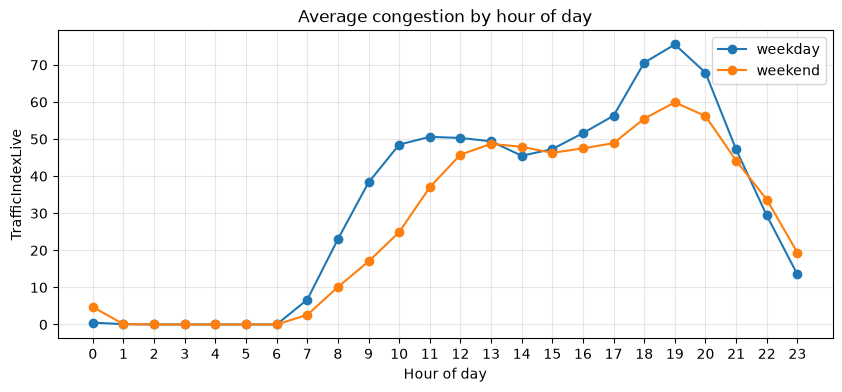

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/bangalore_traffic_weather.csv",
                 parse_dates=["LocalDateTime"]).set_index("LocalDateTime")
df = df.drop(columns=["Country", "City", "UpdateTimeUTC", "LocalDateTimeWeekAgo"])
df = df.asfreq("h")
y = df["TrafficIndexLive"]

is_weekend = df.index.day_of_week >= 5
hourly = pd.DataFrame({
    "weekday": y[~is_weekend].groupby(y[~is_weekend].index.hour).mean(),
    "weekend": y[is_weekend].groupby(y[is_weekend].index.hour).mean(),
}).round(1)

print(hourly.to_string())
print("\nPeak hour, weekday:", hourly["weekday"].idxmax(), "| weekend:", hourly["weekend"].idxmax())

hourly.plot(figsize=(10, 4), marker="o", title="Average congestion by hour of day")
plt.xlabel("Hour of day"); plt.ylabel("TrafficIndexLive"); plt.xticks(range(0, 24))
plt.grid(alpha=0.3); plt.show()

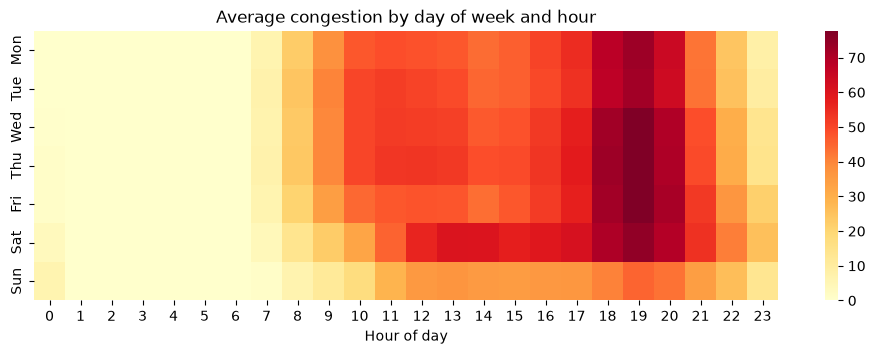

Daily average congestion:
Mon    30.6
Tue    31.3
Wed    33.1
Thu    33.6
Fri    32.5
Sat    33.8
Sun    20.4

Peak (evening 6-9 pm) average by day:
Mon    62.1
Tue    61.5
Wed    67.1
Thu    67.5
Fri    68.3
Sat    67.1
Sun    40.8


In [2]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

pivot = df.pivot_table(values="TrafficIndexLive",
                       index=df.index.day_of_week,
                       columns=df.index.hour,
                       aggfunc="mean")
pivot.index = days

plt.figure(figsize=(12, 3.5))
sns.heatmap(pivot, cmap="YlOrRd")
plt.title("Average congestion by day of week and hour")
plt.xlabel("Hour of day"); plt.show()

print("Daily average congestion:")
print(y.groupby(y.index.day_of_week).mean().round(1).set_axis(days).to_string())

print("\nPeak (evening 6-9 pm) average by day:")
eve = y[y.index.hour.isin([18, 19, 20, 21])]
print(eve.groupby(eve.index.day_of_week).mean().round(1).set_axis(days).to_string())

     2025  2026  change_2026_vs_2025
Jan  31.3  28.2                 -3.1
Feb  30.1  28.5                 -1.6
Mar  29.2  26.0                 -3.2
Apr  31.6  28.6                 -3.0
May  34.0  27.4                 -6.6
Jun  33.9  30.2                 -3.7
Jul  34.9  28.6                 -6.3
Aug  34.2  31.5                 -2.7
Sep  36.2  30.2                 -6.0
Oct  31.2  29.6                 -1.6
Nov  31.4   NaN                  NaN
Dec  29.7   NaN                  NaN


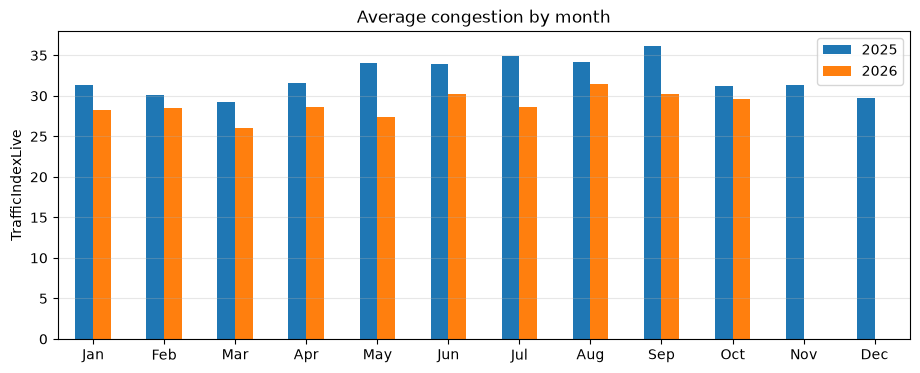


Overall average, Jan-Oct only (same months in both years):
LocalDateTime
2025    32.7
2026    28.9


In [3]:
monthly = y.groupby([y.index.year, y.index.month]).mean().unstack(0).round(1)
monthly.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly.columns = ["2025", "2026"]
monthly["change_2026_vs_2025"] = (monthly["2026"] - monthly["2025"]).round(1)
print(monthly.to_string())

monthly[["2025", "2026"]].plot(kind="bar", figsize=(11, 4), title="Average congestion by month")
plt.ylabel("TrafficIndexLive"); plt.xticks(rotation=0); plt.grid(axis="y", alpha=0.3); plt.show()

print("\nOverall average, Jan-Oct only (same months in both years):")
same = y[y.index.month <= 10]
print(same.groupby(same.index.year).mean().round(1).to_string())

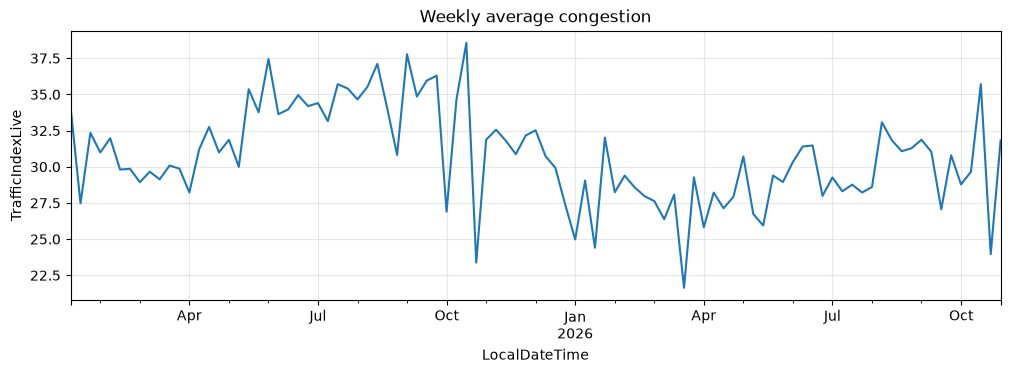

Quarterly averages:
LocalDateTime
2025-03-31    30.1
2025-06-30    33.1
2025-09-30    35.1
2025-12-31    30.7
2026-03-31    27.5
2026-06-30    28.7
2026-09-30    30.1
2026-12-31    29.6
Freq: QE-DEC

Jan-Oct average by year:
LocalDateTime
2025    32.7
2026    28.9

Share of zero hours, Jan-Oct:
LocalDateTime
2025    0.280
2026    0.285

Hourly profile, 2025 vs 2026:
               2025  2026  diff
LocalDateTime                  
0               1.9   1.6  -0.3
1               0.1   0.1   0.0
2               0.0   0.0   0.0
3               0.0   0.0   0.0
4               0.0   0.0   0.0
5               0.0   0.0   0.0
6               0.0   0.0   0.0
7               6.7   4.5  -2.2
8              21.5  17.3  -4.2
9              33.8  31.5  -2.3
10             46.8  36.9  -9.9
11             50.4  43.4  -7.0
12             52.2  46.0  -6.2
13             52.2  46.4  -5.8
14             48.9  43.5  -5.4
15             50.0  43.7  -6.3
16             53.7  47.1  -6.6
17             57.0  51

In [4]:
# 1. Weekly average over time
weekly = y.resample("W").mean()
weekly.plot(figsize=(12, 3.5), title="Weekly average congestion")
plt.ylabel("TrafficIndexLive"); plt.grid(alpha=0.3); plt.show()

# 2. Quarterly averages
print("Quarterly averages:")
print(y.resample("QE").mean().round(1).to_string())

# 3. Same months only (Jan-Oct), by year
same = y[y.index.month <= 10]
print("\nJan-Oct average by year:")
print(same.groupby(same.index.year).mean().round(1).to_string())

# 4. Share of zero hours by year (Jan-Oct)
print("\nShare of zero hours, Jan-Oct:")
print((same == 0).groupby(same.index.year).mean().round(3).to_string())

# 5. Where is the drop? Compare the hourly profile, Jan-Oct 2025 vs 2026
prof = same.groupby([same.index.year, same.index.hour]).mean().unstack(0).round(1)
prof.columns = ["2025", "2026"]
prof["diff"] = (prof["2026"] - prof["2025"]).round(1)
print("\nHourly profile, 2025 vs 2026:")
print(prof.to_string())

In [5]:
d = df[["TrafficIndexLive", "is_raining", "rain_3h"]].copy()
d["year_month"] = d.index.to_period("M")
d["is_sunday"] = d.index.day_of_week == 6
d["hour"] = d.index.hour

keys = ["year_month", "is_sunday", "hour"]
dry_base = d[d["is_raining"] == 0].groupby(keys)["TrafficIndexLive"].mean().rename("dry_base")
d = d.join(dry_base, on=keys)
d["excess"] = d["TrafficIndexLive"] - d["dry_base"]

day = d[(d["hour"] >= 8) & (d["hour"] <= 21)].dropna(subset=["excess"])

print("Daytime 8am-9pm, extra congestion vs dry hours of the same month/hour/day type:")
print(day.groupby("is_raining")["excess"].agg(["mean", "median", "count"]).round(1).to_string())

eve = day[day["hour"].isin([18, 19, 20, 21])]
print("\nEvening 6-9 pm:")
print(eve.groupby("is_raining")["excess"].agg(["mean", "median", "count"]).round(1).to_string())

print("\nRainy hours only, by hour:")
print(day[day["is_raining"] == 1].groupby("hour")["excess"].agg(["mean", "count"]).round(1).to_string())

Daytime 8am-9pm, extra congestion vs dry hours of the same month/hour/day type:
            mean  median  count
is_raining                     
0           -0.0     0.4   8714
1            2.8     1.6    523

Evening 6-9 pm:
            mean  median  count
is_raining                     
0           -0.0     0.0   2511
1            6.8     4.8    129

Rainy hours only, by hour:
      mean  count
hour             
8      0.3     12
9     -0.7     10
10     5.0     15
11     1.4     14
12    -4.4     19
13    -3.1     32
14     0.4     56
15     2.9     74
16     2.0     86
17     3.5     76
18     6.2     48
19     5.2     33
20    10.0     26
21     6.9     22


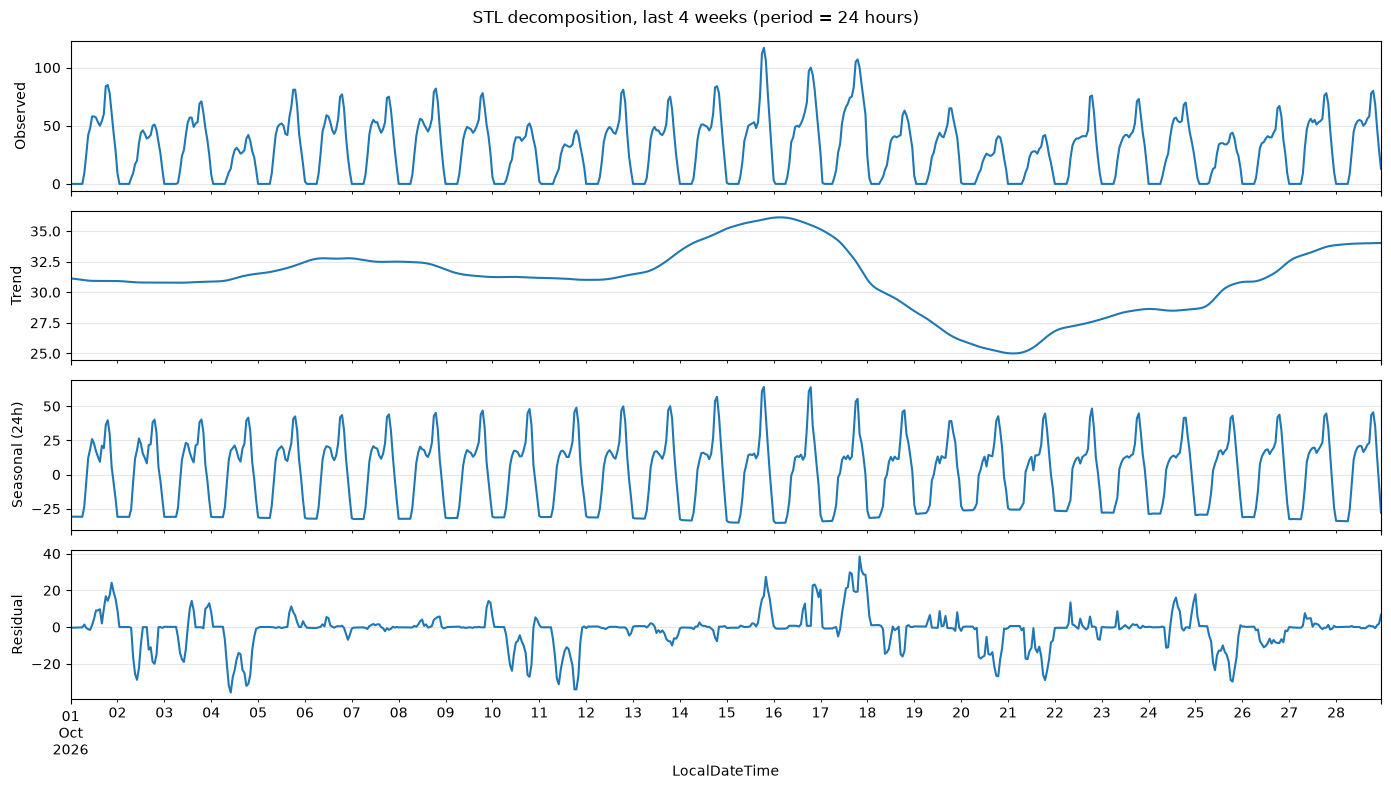

Strength of daily seasonality (0 to 1): 0.896
Strength of trend (0 to 1):             0.187

Residual summary:
count    15829.00
mean        -1.01
std          8.35
min        -51.35
25%         -0.74
50%         -0.06
75%          0.61
max         99.10

Largest 10 residuals:
LocalDateTime
2026-04-29 19:00:00    2026-04-29 19:00
2026-04-29 20:00:00    2026-04-29 20:00
2026-04-29 21:00:00    2026-04-29 21:00
2026-04-29 22:00:00    2026-04-29 22:00
2026-04-29 18:00:00    2026-04-29 18:00
2026-04-29 23:00:00    2026-04-29 23:00
2026-04-29 17:00:00    2026-04-29 17:00
2025-09-21 19:00:00    2025-09-21 19:00
2025-09-21 18:00:00    2025-09-21 18:00
2025-05-17 18:00:00    2025-05-17 18:00


In [6]:
from statsmodels.tsa.seasonal import STL

res = STL(y, period=24, robust=True).fit()

# Plot the last 4 weeks
last = slice(-24 * 28, None)
fig, ax = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
for a, (name, s) in zip(ax, [("Observed", y), ("Trend", res.trend),
                             ("Seasonal (24h)", res.seasonal), ("Residual", res.resid)]):
    s.iloc[last].plot(ax=a); a.set_ylabel(name); a.grid(alpha=0.3)
plt.suptitle("STL decomposition, last 4 weeks (period = 24 hours)")
plt.tight_layout(); plt.show()

# How much of the variation is each component?
seasonal_strength = max(0, 1 - res.resid.var() / (res.seasonal + res.resid).var())
trend_strength = max(0, 1 - res.resid.var() / (res.trend + res.resid).var())
print("Strength of daily seasonality (0 to 1):", round(seasonal_strength, 3))
print("Strength of trend (0 to 1):            ", round(trend_strength, 3))

print("\nResidual summary:")
print(res.resid.describe().round(2).to_string())

# Where are the biggest residuals?
print("\nLargest 10 residuals:")
print(res.resid.abs().nlargest(10).index.to_series().dt.strftime("%Y-%m-%d %H:%M").to_string())

ADF: p below 0.05 suggests stationary.  KPSS: p above 0.05 suggests stationary.

Original series                  ADF p = 0.0000   KPSS p = 0.0100
Seasonal difference (24h)        ADF p = 0.0000   KPSS p = 0.1000
Seasonal difference (168h)       ADF p = 0.0000   KPSS p = 0.1000

Autocorrelation at key lags:
  lag   1: 0.935
  lag   2: 0.776
  lag   3: 0.570
  lag   6: -0.005
  lag  12: -0.734
  lag  24: 0.900
  lag  48: 0.875
  lag 168: 0.928


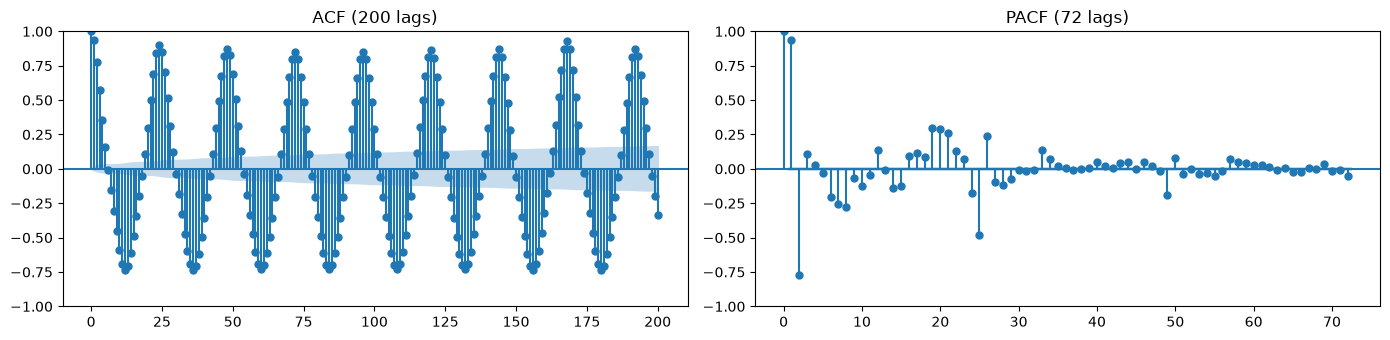

In [7]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")

def tests(series, label):
    adf_p = adfuller(series.dropna())[1]
    kpss_p = kpss(series.dropna(), nlags="auto")[1]
    print(f"{label:<32} ADF p = {adf_p:.4f}   KPSS p = {kpss_p:.4f}")

print("ADF: p below 0.05 suggests stationary.  KPSS: p above 0.05 suggests stationary.\n")
tests(y, "Original series")
tests(y.diff(24), "Seasonal difference (24h)")
tests(y.diff(168), "Seasonal difference (168h)")

# Autocorrelation at key lags
a = acf(y, nlags=170)
print("\nAutocorrelation at key lags:")
for lag in [1, 2, 3, 6, 12, 24, 48, 168]:
    print(f"  lag {lag:>3}: {a[lag]:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(y, lags=200, ax=ax[0]); ax[0].set_title("ACF (200 lags)")
plot_pacf(y, lags=72, ax=ax[1], method="ywm"); ax[1].set_title("PACF (72 lags)")
plt.tight_layout(); plt.show()

In [8]:
cols = ["TrafficIndexLive", "TrafficIndexWeekAgo", "JamsCount", "JamsLengthInKms",
        "JamsDelay", "TravelTimeLivePer10KmsMins", "precipitation", "temperature_2m"]

print("29 April 2026, afternoon to night:")
print(df.loc["2026-04-29 14:00":"2026-04-30 02:00", cols].round(1).to_string())

print("\n7 pm readings, 24 Apr to 4 May 2026:")
print(y.loc["2026-04-24":"2026-05-04"][lambda s: s.index.hour == 19].to_string())

wed19 = y[(y.index.day_of_week == 2) & (y.index.hour == 19)]
print("\nAll Wednesdays at 7 pm: median", wed19.median(), "| 95th percentile", wed19.quantile(0.95), "| max", wed19.max())

29 April 2026, afternoon to night:
                     TrafficIndexLive  TrafficIndexWeekAgo  JamsCount  JamsLengthInKms  JamsDelay  TravelTimeLivePer10KmsMins  precipitation  temperature_2m
LocalDateTime                                                                                                                                               
2026-04-29 14:00:00              43.0                 44.0       55.0             19.9      178.2                        34.8            0.0            35.5
2026-04-29 15:00:00              38.0                 45.0       49.0             19.7      177.5                        33.5            0.0            35.6
2026-04-29 16:00:00              45.0                 49.0       70.0             30.6      236.2                        35.2            0.0            35.1
2026-04-29 17:00:00             102.0                 52.0      302.0            159.9     1530.7                        49.8            0.0            30.2
2026-04-29 18:00:00    